## Test file of the GCN Model

In [1]:
import torch
from torch_geometric.nn import GCNConv, GATConv
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F


In [18]:

# GCN - 01
class GCN(torch.nn.Module):
    def __init__(self):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(5, 32)  # 5 features 
        self.conv2 = GCNConv(32, 64)
        self.conv3 = GCNConv(64, 1) 

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = self.conv3(x, edge_index)  

        return x
  

In [19]:
#GAT - 02
class GAT(torch.nn.Module):
    def __init__(self):
        super(GAT, self).__init__()
        self.conv1 = GATConv(5, 128)
        self.conv2 = GATConv(128, 256)
        self.conv3 = GATConv(256, 1)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = self.conv3(x, edge_index)

        return x

In [3]:
import os
from torch_geometric.data import Data
from torch_geometric.nn import knn_graph
def load_data_and_create_graphs(data_folder_path, labels_folder_path, output_folder_path, n, outputlist, K):
    os.makedirs(output_folder_path, exist_ok=True)
    for output in outputlist:
        data_path = f"{data_folder_path}obs_matrices_snapshot_{output:04d}.npy"
        label_path = f"{labels_folder_path}B_L_snapshot_{output:04d}.npy"

        data_matrix3d = np.load(data_path)
        label_matrix = np.load(label_path)
        
        for i in range(n):
            data_matrix = data_matrix3d[i][:,:5] # Use only the first 5 feature vithout the v_los
            
            edge_index = knn_graph(torch.tensor(data_matrix, dtype=torch.float), k=K, loop=False)
            graph_data = Data(x=torch.tensor(data_matrix, dtype=torch.float), edge_index=edge_index)
            label = torch.tensor(label_matrix, dtype=torch.float)
            
            torch.save(graph_data, f'{output_folder_path}/graph_data_output_{output}_rotation_{i}.pt')
            torch.save(label, f'{output_folder_path}/label_output_{output}_rotation_{i}.pt')


In [168]:
IC_goal = "IC_81/"
data_folder_path = os.path.join("../obs_all_stars/", IC_goal)
labels_folder_path = os.path.join("../labels_bound_stars/", IC_goal)
outputlist = [0, 25, 50, 75, 100]
n_rotations = 2
K = 20

load_data_and_create_graphs(data_folder_path, labels_folder_path, "graphs",n_rotations, outputlist, K)

In [169]:
  
#load the model
model = GCN()

model.load_state_dict(torch.load('GCN-02/best_gnn_model_02.pth')) 
model.eval() 

# load a test graph
output_target = 100
output_rotation = 0

data = torch.load(f'graphs/graph_data_output_{output_target}_rotation_{output_rotation}.pt')
target_tensor = torch.load(f'graphs/label_output_{output_target}_rotation_{output_rotation}.pt')
true_labels = target_tensor.numpy().astype(int)

# getting the probabilities and predictions
with torch.no_grad():
    out = model(data)
    out = out.squeeze()
    
    # sigmoïd because BCEWithLogitsLoss
    probs = torch.sigmoid(out)
    # decision threshold at 0.5
    preds = (probs > 0.5).int().numpy()


In [163]:
from adri_plotstyle import init_plot_style
init_plot_style(14)


✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


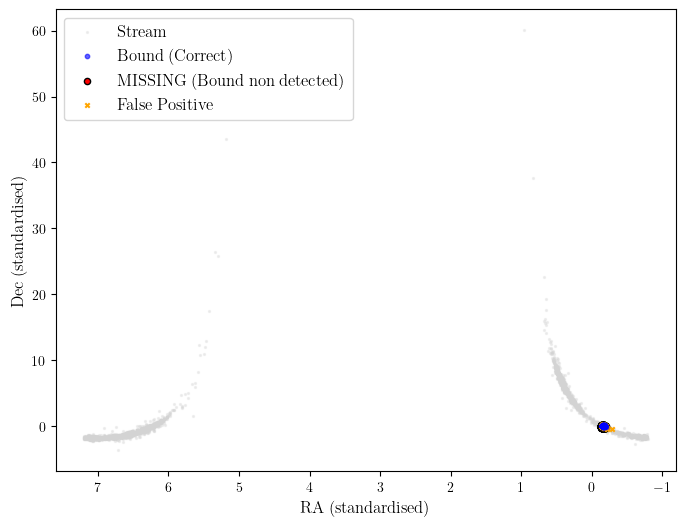

True Positives: 238
True Negatives: 9280
False Positives: 108
Missed Bound: 33364
Accuracy: 22.14%
Error Percentage: 77.86%


In [170]:

# right identification of bound 
true_positives = (true_labels == 1) & (preds == 1)
# bound stars but not predicte by the model 
missed_bound = (true_labels == 1) & (preds == 0)
# right unbound stars 
true_negatives = (true_labels == 0) & (preds == 0)

false_positives = (true_labels == 0) & (preds == 1)

#Plot
ra = data.x[:, 0].numpy()
dec = data.x[:, 1].numpy()

plt.figure(figsize=(8, 6))

plt.scatter(ra[true_negatives], dec[true_negatives], c='lightgray', s=2, alpha=0.3, label='$\mathrm{Stream}$')

# Bound correct
plt.scatter(ra[true_positives], dec[true_positives], c='blue', s=10, alpha=0.6, label='$\mathrm{Bound\ (Correct)}$', zorder = 5)

# Forgotten ones 
plt.scatter(ra[missed_bound], dec[missed_bound], c='red', s=20, edgecolors='black', label='$\mathrm{MISSING\ (Bound\ non\ detected)}$')

# false bound
plt.scatter(ra[false_positives], dec[false_positives], c='orange', s=10, marker='x', label='$\mathrm{False\ Positive}$', zorder = 2)

plt.gca().invert_xaxis() # Convention Astro
plt.xlabel('$\mathrm{RA\ (standardised)}$')
plt.ylabel('$\mathrm{Dec\ (standardised)}$')
plt.legend()
plt.show()
print(f"True Positives: {true_positives.sum()}")
print(f"True Negatives: {true_negatives.sum()}")
print(f"False Positives: {false_positives.sum()}")
print(f"Missed Bound: {missed_bound.sum()}")

# accuracy of the model 
accuracy = 100 * (true_positives.sum() + true_negatives.sum()) / len(true_labels)
print(f"Accuracy: {accuracy:.2f}%")
# percentage of error
error_percentage = 100 * (false_positives.sum() + missed_bound.sum()) / len(true_labels)
print(f"Error Percentage: {error_percentage:.2f}%")

## Making same plot but plotting the real data in certesian coordinates with the computed masks 

In [73]:
import h5py
def load_snapshot(fname, shift):
    # Load snapshot data from a given file and apply a shift to the particle positions.
    # returns particle positions, masses, and time of the snapshot
    f = h5py.File(fname, "r")
    pos = np.array(f["DMParticles"]["Coordinates"]) - shift
    vel = np.array(f["DMParticles"]["Velocities"])

    time = (
        f["Header"].attrs["Time"][0]
        * f["Units"].attrs["Unit time in cgs (U_t)"][0]
        / 31557600.0e9
    )
    mass = np.array(f["DMParticles"]["Masses"])
    return pos, vel, mass, time

In [171]:
path = "/Volumes/Adrian 1 SS/MA2/TP4b/outputs_SWIFT_jed/withoutDF/IC_81"
save_folder = "Plots"
if not os.path.exists(save_folder):
    os.makedirs(save_folder)

output = [f for f in os.listdir(path) if f.startswith("snapshot_0100")]
fname = os.path.join(path, output[0])
pos, vel, _, _ = load_snapshot(fname, shift=500.0)

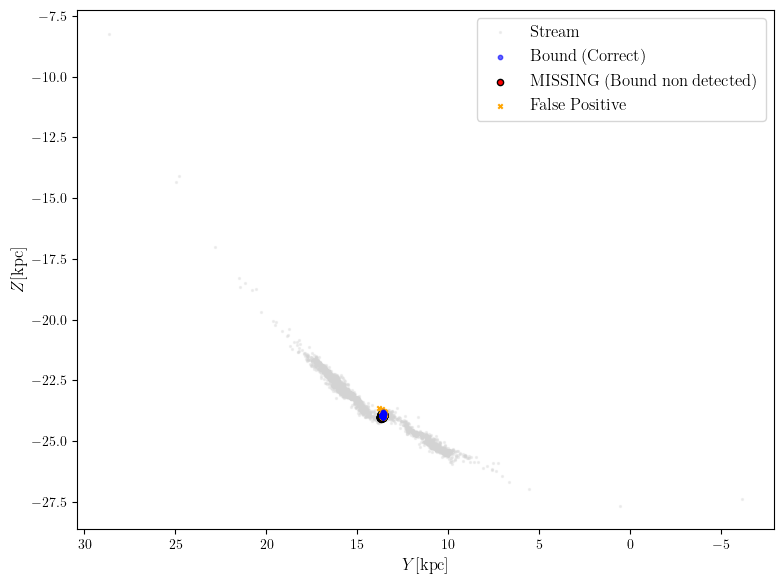

True Positives: 238
True Negatives: 9280
False Positives: 108
Missed Bound: 33364
Accuracy: 22.14%
Error Percentage: 77.86%


In [172]:
# right identification of bound 
true_positives = (true_labels == 1) & (preds == 1)
# bound stars but not predicte by the model 
missed_bound = (true_labels == 1) & (preds == 0)
# right unbound stars 
true_negatives = (true_labels == 0) & (preds == 0)

false_positives = (true_labels == 0) & (preds == 1)

#Plot
x = pos[:, 1]
y = pos[:, 2]

plt.figure(figsize=(8, 6))

plt.scatter(x[true_negatives], y[true_negatives], c='lightgray', s=2, alpha=0.3, label='$\mathrm{Stream}$')

# Bound correct
plt.scatter(x[true_positives], y[true_positives], c='blue', s=10, alpha=0.6, label='$\mathrm{Bound\ (Correct)}$', zorder = 5)

# Forgotten ones 
plt.scatter(x[missed_bound], y[missed_bound], c='red', s=20, edgecolors='black', label='$\mathrm{MISSING\ (Bound\ non\ detected)}$')

# false bound
plt.scatter(x[false_positives], y[false_positives], c='orange', s=10, marker='x', label='$\mathrm{False\ Positive}$', zorder = 2)

plt.gca().invert_xaxis() # Convention Astro
plt.xlabel('$Y\mathrm{[kpc]}$')
plt.ylabel('$Z\mathrm{[kpc]}$')
plt.tight_layout()
plt.legend()
plt.show()
print(f"True Positives: {true_positives.sum()}")
print(f"True Negatives: {true_negatives.sum()}")
print(f"False Positives: {false_positives.sum()}")
print(f"Missed Bound: {missed_bound.sum()}")

# accuracy of the model 
accuracy = 100 * (true_positives.sum() + true_negatives.sum()) / len(true_labels)
print(f"Accuracy: {accuracy:.2f}%")
# percentage of error
error_percentage = 100 * (false_positives.sum() + missed_bound.sum()) / len(true_labels)
print(f"Error Percentage: {error_percentage:.2f}%")

/var/folders/kg/kymk84z91rsglqgxbnc85_8r0000gn/T/ipykernel_84180/1736519787.py:45: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for handle in lgnd.legendHandles:


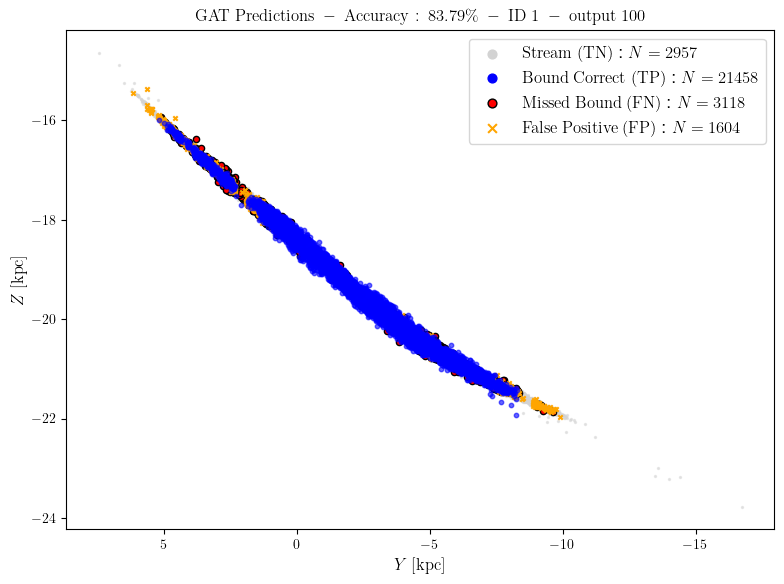

Error Percentage: 16.21%


In [128]:
import matplotlib.pyplot as plt

# 1. On calcule les nombres à l'avance pour alléger le code du plot
tn_count = true_negatives.sum()
tp_count = true_positives.sum()
fn_count = missed_bound.sum()
fp_count = false_positives.sum()

total_stars = len(true_labels)
accuracy = 100 * (tp_count + tn_count) / total_stars

# 2. Création de la figure
plt.figure(figsize=(8, 6))

# Stream (Vrais Négatifs)
plt.scatter(x[true_negatives], y[true_negatives], 
            c='lightgray', s=2, alpha=0.5, 
            label=rf'$\mathrm{{Stream\ (TN)}}$ : $N={tn_count}$')

# Bound correct (Vrais Positifs)
plt.scatter(x[true_positives], y[true_positives], 
            c='blue', s=10, alpha=0.6, zorder=5, 
            label=rf'$\mathrm{{Bound\ Correct\ (TP)}}$ : $N={tp_count}$')

# Missed bound (Faux Négatifs)
plt.scatter(x[missed_bound], y[missed_bound], 
            c='red', s=20, edgecolors='black', 
            label=rf'$\mathrm{{Missed\ Bound\ (FN)}}$ : $N={fn_count}$')

# False bound (Faux Positifs)
plt.scatter(x[false_positives], y[false_positives], 
            c='orange', s=10, marker='x', zorder=2, 
            label=rf'$\mathrm{{False\ Positive\ (FP)}}$ : $N={fp_count}$')

# 3. Esthétique et axes
plt.gca().invert_xaxis() # Convention Astro
plt.xlabel('$Y\ \mathrm{[kpc]}$') # Espace ajouté avant [kpc] pour faire plus propre
plt.ylabel('$Z\ \mathrm{[kpc]}$')
plt.title(rf'$\mathrm{{GAT\ Predictions\ -\ Accuracy:\ {accuracy:.2f}\%\ -\ ID\ 1\ -\ output\ 100}}$', fontsize=12)

# 4. Optimisation de la légende (TRÈS IMPORTANT)
lgnd = plt.legend(loc='best', frameon=True)

# On force la taille et l'opacité des points dans la légende pour qu'ils soient lisibles
for handle in lgnd.legendHandles:
    handle.set_sizes([40.0])  # Taille uniforme et visible
    handle.set_alpha(1.0)     # Finit la transparence juste pour la légende

plt.tight_layout()
plt.savefig("prediction_GAT_ID1_output25.png", dpi=600)
plt.show()


# Tu peux garder tes prints si tu en as besoin pour la console
error_percentage = 100 * (fp_count + fn_count) / total_stars
print(f"Error Percentage: {error_percentage:.2f}%")

In [156]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

def get_first_perigalacticon(orbit_filepath):
    data = np.loadtxt(orbit_filepath, skiprows=1)
    x, y, z = data[:, 1], data[:, 2], data[:, 3]
    R = np.sqrt(x**2 + y**2 + z**2)
    local_min_indices = argrelextrema(R, np.less)[0]
    
    if len(local_min_indices) > 0:
        return R[local_min_indices[0]]
    else:
        return R.min()

model = GCN()
model.load_state_dict(torch.load('GCN-01/best_gnn_model_01.pth')) 
model.eval()

snapshot_target = 100
rotation_target = 0
K = 20
IC_list = [
    "IC_1", "IC_3", "IC_4", "IC_5", "IC_6", "IC_8", "IC_9", "IC_11", "IC_12", 
    "IC_13", "IC_14", "IC_15", "IC_16", "IC_17", "IC_18", "IC_19", "IC_20", 
    "IC_21", "IC_22", "IC_23", "IC_24", "IC_25", "IC_26", "IC_28", "IC_29", 
    "IC_30", "IC_31", "IC_32", "IC_33", "IC_34", "IC_35", "IC_36", "IC_37", 
    "IC_38", "IC_39", "IC_40", "IC_41", "IC_42", "IC_43", "IC_44", "IC_46", 
    "IC_47", "IC_48", "IC_50", "IC_51", "IC_52", "IC_53", "IC_54", "IC_55", 
    "IC_59", "IC_60", "IC_61", "IC_62", "IC_63", "IC_64", "IC_65", "IC_66", 
    "IC_68", "IC_69", "IC_70", "IC_71", "IC_72", "IC_73", "IC_74", "IC_75", 
    "IC_76", "IC_77", "IC_78", "IC_79", "IC_80", "IC_81", "IC_82", "IC_83", 
    "IC_86", "IC_87"
]

results = []

for ic in IC_list:
    ic_number = int(ic.split('_')[1])
    #change ic to ID
    id = f"ID_{ic_number}"
    orbit_path = os.path.join("../../make_ICs/orbits/", f"orbit_{ic_number}.txt")
    rp1 = get_first_perigalacticon(orbit_path)
    
    data_folder_path = os.path.join("../obs_all_stars/", f"{ic}/")
    labels_folder_path = os.path.join("../labels_bound_stars/", f"{ic}/")
    
    load_data_and_create_graphs(data_folder_path, labels_folder_path, "graphs", 1, [snapshot_target], K)
    
    graph_path = f'graphs/graph_data_output_{snapshot_target}_rotation_{rotation_target}.pt'
    label_path = f'graphs/label_output_{snapshot_target}_rotation_{rotation_target}.pt'
    
    data = torch.load(graph_path)
    target_tensor = torch.load(label_path)
    true_labels = target_tensor.numpy().astype(int)
    
    os.remove(graph_path)
    os.remove(label_path)
    
    with torch.no_grad():
        out = model(data).squeeze()
        probs = torch.sigmoid(out)
        preds = (probs > 0.5).int().numpy()
    
    error_rate = 100 * np.mean(preds != true_labels)
    
    results.append({
        'ID': id,
        'Rp1': rp1,
        'Error_Percentage': error_rate
    })


In [157]:

df = pd.DataFrame(results)
df_sorted = df.sort_values(by='Rp1')


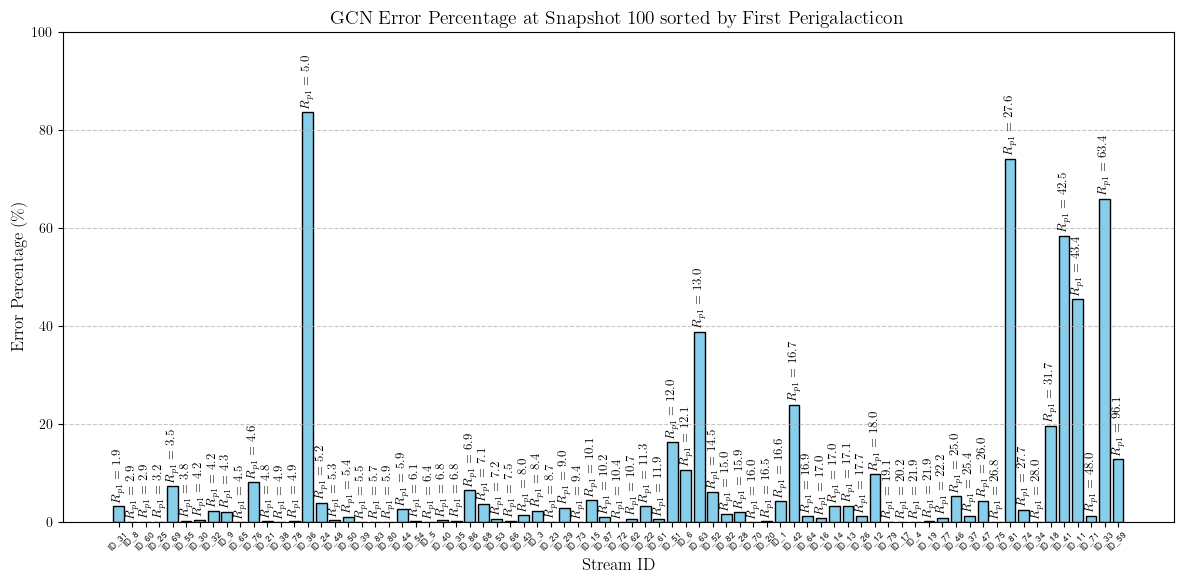

In [159]:

plt.figure(figsize=(12, 6))
bars = plt.bar(df_sorted['ID'], df_sorted['Error_Percentage'], color='skyblue', edgecolor='black')

plt.title(f"$\mathrm{{GCN\ Error\ Percentage\ at\ Snapshot\ {snapshot_target}\ sorted\ by\ First\ Perigalacticon}}$", fontsize=14)
plt.ylabel("$\mathrm{{Error\ Percentage\ (\%)}}$", fontsize=12)
plt.xlabel("$\mathrm{{Stream\ ID}}$", fontsize=12)
plt.xticks(rotation=45,fontsize=6)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar, rp1_val in zip(bars, df_sorted['Rp1']):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, 
             f"$R_{{p1}}={rp1_val:.1f}$", 
             ha='center', va='bottom', fontsize=9, rotation=90)

plt.tight_layout()
plt.savefig("GCN_error_percentage_by_perigalacticon.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


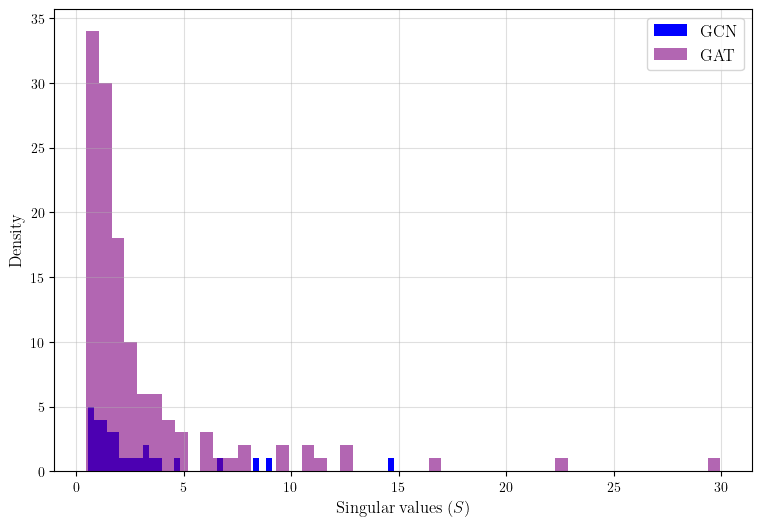

In [31]:
import matplotlib.pyplot as plt
import torch
from adri_plotstyle import init_plot_style
init_plot_style(14)

plt.figure(figsize=(9, 6))
plt.grid(True, alpha=0.4)

model1 = GCN()
model1.load_state_dict(torch.load('GCN-01/best_gnn_model_01.pth')) 
model1.eval() 

weights = model1.conv2.lin.weight.detach().cpu()
U, S, Vh = torch.linalg.svd(weights)
singular_values = S.numpy()
plt.hist(singular_values, bins=50, color='blue', alpha=1.0, label='$\mathrm{GCN}$')


model2 = GAT()
model2.load_state_dict(torch.load('GCN-02/best_gnn_model_02.pth')) 
model2.eval() 

weights = model2.conv2.lin.weight.detach().cpu()
U, S, Vh = torch.linalg.svd(weights)
singular_values = S.numpy()
plt.hist(singular_values, bins=50, color='purple', alpha=0.6, label='$\mathrm{GAT}$')


plt.xlabel("$\mathrm{Singular\ values\ }(S)$")
plt.ylabel("$\mathrm{Density}$")
plt.legend()
plt.savefig("spectral_analysis_GNN.png", dpi = 600)